# Drawdown examples
This notebook reproduces the results in the README: the maximum drawdown, bottom date and recovery date for SPY and QQQ, plus a chart of each drawdown over time. It uses `drawdown_stats` from `drawdown.py` in this repository.

**Data:** daily dividend-adjusted closing prices from Yahoo Finance (via yfinance), January 2015 to December 2025.

## Data
Download daily adjusted closes for each ticker in `TICKERS`. To analyze another asset, add its symbol to the list.

In [1]:
import yfinance as yf
import pandas as pd

prices = pd.DataFrame()
TICKERS = ["SPY", "QQQ"]

for ticker in TICKERS:
    prices[ticker] = yf.download(ticker, start="2015-01-01", end="2025-12-31", auto_adjust=True)["Close"]

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


## Load the function
Import `drawdown_stats` directly from the repository, so this notebook always uses the same version as `drawdown.py`.

In [2]:
!wget -q https://raw.githubusercontent.com/mmcanally7/quant-research/master/drawdown.py
from drawdown import drawdown_stats

## Results
Max drawdown is the largest percentage fall from a previous peak. The recovery date is the first day the price closed back at that peak.

In [3]:
rows = []

for ticker in TICKERS:
    max_dd, bottom_date, recovery_date = drawdown_stats(prices[ticker])
    rows.append({
        "Ticker": ticker,
        "Max Drawdown (%)": max_dd,
        "Bottom Date": bottom_date,
        "Recovery Date": recovery_date,
    })

results = pd.DataFrame(rows).set_index("Ticker")
results["Max Drawdown (%)"] = (results["Max Drawdown (%)"] * 100).round(1)
results

,Max Drawdown (%),Bottom Date,Recovery Date
Ticker,,,
SPY,-33.7,2020-03-23,2020-08-10
QQQ,-35.1,2022-11-03,2023-12-13


QQQ's worst drawdown (−35.1%) was slightly deeper than SPY's (−33.7%), and it came in a different crisis: 2022 for QQQ, 2020 for SPY. Recovery times differ far more than depths. SPY regained its peak about five months after the 2020 bottom, while QQQ needed over a year after its 2022 bottom.

## Drawdowns over time
Each line shows how far the price sits below its running peak; 0% means a new high.

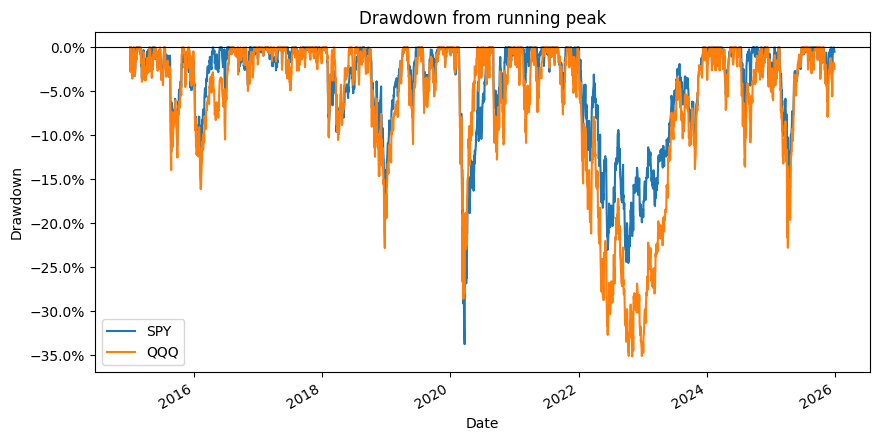

In [4]:
import matplotlib.pyplot as plt

drawdowns = prices / prices.cummax() - 1    # one column per ticker

ax = drawdowns.plot(figsize=(10, 5))
ax.set_title("Drawdown from running peak")
ax.set_ylabel("Drawdown")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.axhline(0, color="black", linewidth=0.8)

plt.savefig("drawdowns.png", dpi=150, bbox_inches="tight")
plt.show()

The chart shows what the table can't. The 2020 crash was a sharp V for both funds, and QQQ recovered first. In 2022 the order reversed: QQQ fell much further and stayed below its peak longer, with two nearly equal lows in November and December. QQQ's line is also more jagged throughout, reflecting its higher volatility. Depth alone understates how different these two drawdowns were to live through.

## Tests
Check the function on small series where the answer can be worked out by hand.

In [5]:
toy = pd.Series([100, 120, 90, 110], index=pd.date_range("2020-01-01", periods=4))
drawdown_stats(toy)   # expected: (-0.25, 2020-01-03, None), never recovered

The stock has yet to recover.


(-0.25, Timestamp('2020-01-03 00:00:00'), None)